# 02 · Modelo nulo: decomposição da variância

Na seleção por etapas (*step-up*) de modelos multinível, o modelo nulo contém apenas o intercepto na parte fixa e reparte a variância da resposta entre os componentes do modelo (Raudenbush & Bryk, 2002). As observações semanais estão aninhadas nos pares loja × produto, e os pares pertencem a dois agrupamentos cruzados, loja e produto (Baayen et al., 2008). O ajuste foi feito com as 104 semanas iniciais de treino (D11 revisada).

As duas versões do notebook leem a mesma execução, gravada por `scripts/fit_null_models.py` em `outputs/runs/null_models`.

*Dados: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "pt"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import viz
from retail_multilevel.i18n import t
from retail_multilevel.paths import PROCESSED_DIR
from retail_multilevel.runs import load_run

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.4f}".format)
run = load_run("null_models", "20261124-114105-b15be79c")
print(t("data_credit", LANG))
print("run:", run.run_id, "| finished_at:", run.metadata["finished_at"])
sample = run.load_json("sample")
display(pd.Series(sample).to_frame("training sample"))

Dados: dunnhumby Source Files – Breakfast at the Frat
run: 20261124-114105-b15be79c | finished_at: 2026-11-24T11:41:55.743542


,training sample
nobs,347092
n_stores,77
n_products,55
n_pairs,3859
first_week,2009-01-14 00:00:00
last_week,2011-01-05 00:00:00


O identificador e o horário de término da execução são mostrados acima. O treino reúne 347.092 linhas, 77 lojas, 55 produtos e 3.859 pares, de 2009-01-14 a 2011-01-05.

## 1. Os modelos M0 a M4

Os cinco modelos foram ajustados por REML (Bates et al., 2015). Como todos têm apenas o intercepto na parte fixa, as verossimilhanças REML são comparáveis (Pinheiro & Bates, 2000). M0 é a regressão de nível único (OLS). M1 tem efeito aleatório de loja e M2, de produto. M3 inclui os dois, e M4 acrescenta a interação loja × produto (o par).

In [3]:
fits = run.load_table("fits")
display(fits[["name", "formula"]])

,name,formula
0,M0_ols,LOG_UNITS ~ 1
1,M1_store,LOG_UNITS ~ 1 + (1 | STORE_NUM)
2,M2_product,LOG_UNITS ~ 1 + (1 | UPC)
3,M3_crossed,LOG_UNITS ~ 1 + (1 | STORE_NUM) + (1 | UPC)
4,M4_crossed_pair,LOG_UNITS ~ 1 + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)


## 2. Estatísticas de ajuste

A tabela traz o número de parâmetros, a log-verossimilhança REML, o AIC, o BIC, o tempo de ajuste e o número de mensagens de convergência.

In [4]:
display(fits[["name", "npar", "loglik", "aic", "bic", "seconds", "n_messages"]])

,name,npar,loglik,aic,bic,seconds,n_messages
0,M0_ols,2,"-563,134.7198","1,126,273.4395","1,126,294.9542",0.0418,0
1,M1_store,3,"-551,362.1665","1,102,730.3330","1,102,762.6050",1.6540,0
2,M2_product,3,"-431,259.3269","862,524.6537","862,556.9258",1.6754,0
3,M3_crossed,4,"-389,928.2579","779,864.5158","779,907.5452",6.7715,0
4,M4_crossed_pair,5,"-346,786.4831","693,582.9663","693,636.7530",29.0096,0


A log-verossimilhança sobe de −563.135 (M0) para −346.786 (M4). O AIC cai de 1.126.273 para 693.583, e AIC e BIC diminuem a cada modelo adicionado. Nenhum ajuste gerou mensagens de convergência. O M4 levou cerca de 29 segundos.

## 3. Testes de razão de verossimilhanças

Cada teste compara um modelo restrito com o modelo completo, que tem um componente de variância a mais. Sob a hipótese nula, esse componente é zero, isto é, está na **fronteira** do espaço de parâmetros (σ² = 0), e a estatística não segue um χ² com 1 grau de liberdade. A distribuição de referência é uma mistura 50:50 de χ²₀ e χ²₁ (Self & Liang, 1987; Stram & Lee, 1994), de modo que `p_value` é a metade de `p_naive`.

In [5]:
lr = run.load_table("lr")


def format_p(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"


display(lr.assign(p_value=lr["p_value"].map(format_p), p_naive=lr["p_naive"].map(format_p)))

,restricted,full,stat,df,p_value,p_naive
0,M0_ols,M1_store,"23,545.1065",1,< 1e-300,< 1e-300
1,M0_ols,M2_product,"263,750.7858",1,< 1e-300,< 1e-300
2,M1_store,M3_crossed,"322,867.8172",1,< 1e-300,< 1e-300
3,M2_product,M3_crossed,"82,662.1380",1,< 1e-300,< 1e-300
4,M3_crossed,M4_crossed_pair,"86,283.5495",1,< 1e-300,< 1e-300


As estatísticas vão de 23.545 (M0 contra M1) a 322.868 (M1 contra M3), com valores p abaixo de 1e-300 em todas as comparações. Os testes dão evidência de componentes de variância de loja, produto e interação loja × produto. Com 347.092 linhas de treino, mesmo componentes pequenos podem ser detectados. A decomposição de M4 quantifica a participação de cada componente.

## 4. Correlação intraclasse (ICC)

O gráfico mostra os componentes da variância de log(unidades) em cada modelo de M1 a M4 (Raudenbush & Bryk, 2002). Em cada modelo, as participações somam 1.

,model,group,variance,share
0,M4_crossed_pair,STORE_NUM:UPC,0.1431,0.0849
1,M4_crossed_pair,STORE_NUM,0.1623,0.0963
2,M4_crossed_pair,UPC,0.9646,0.5724
3,M4_crossed_pair,Residual,0.4151,0.2463


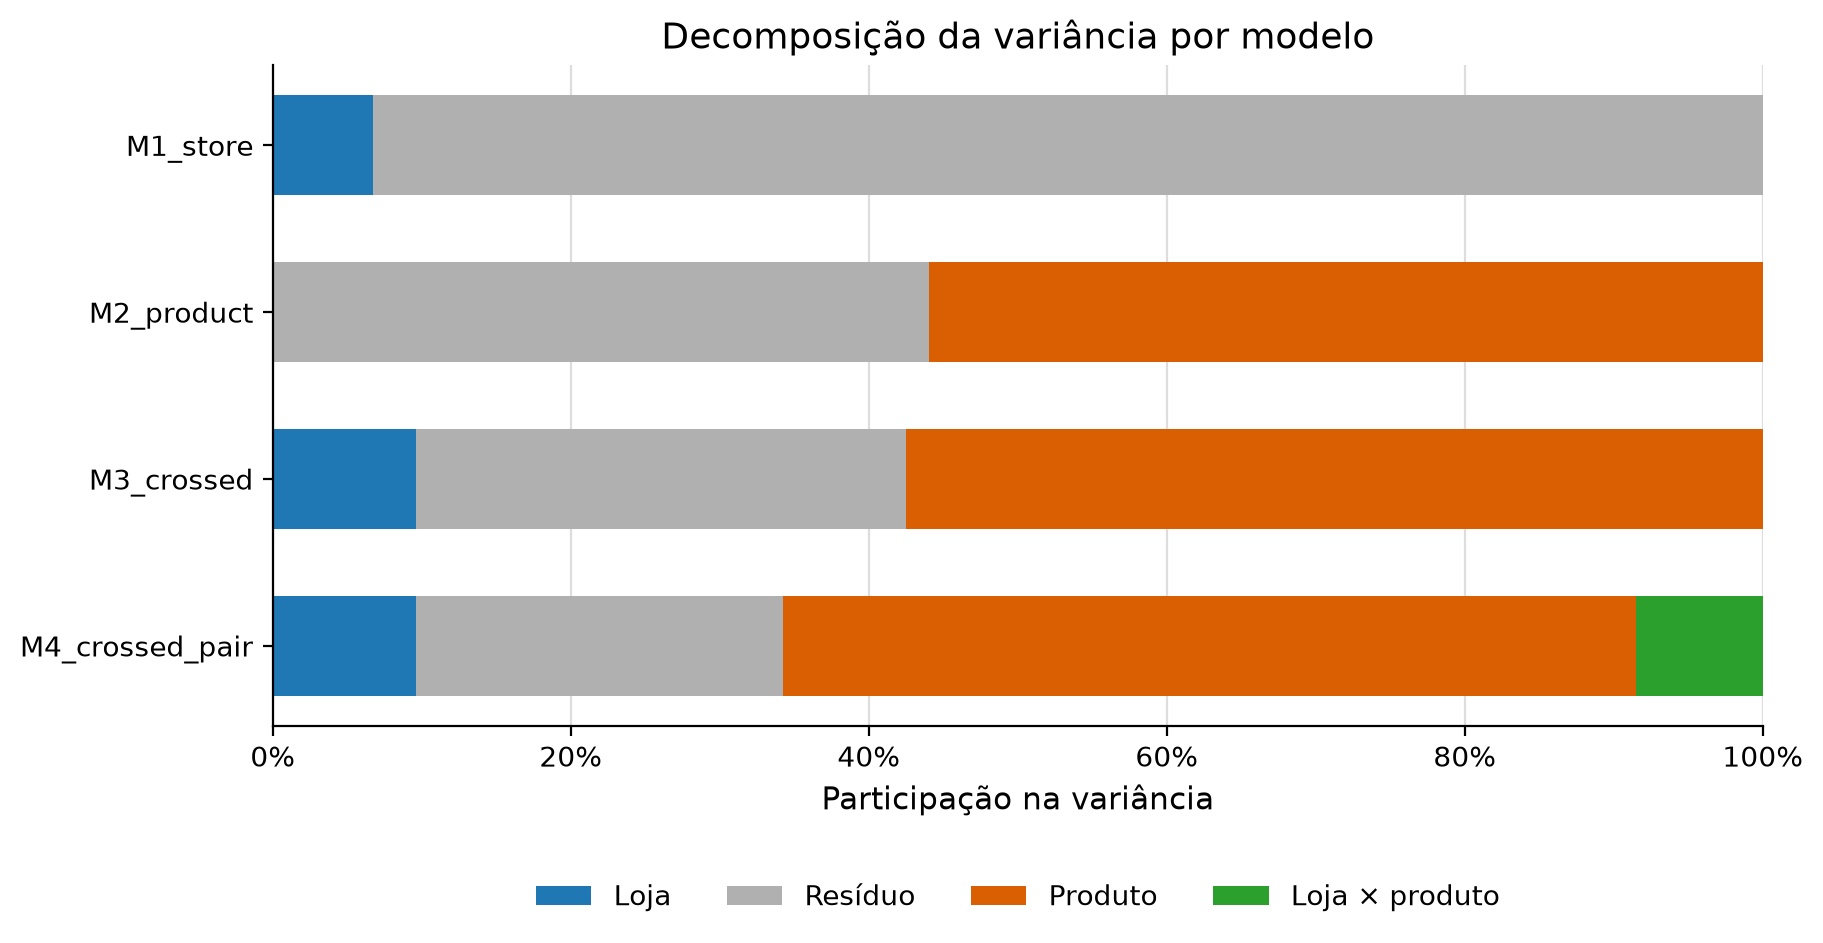

In [6]:
icc = run.load_table("icc")
fig = viz.plot_icc_by_model(icc, LANG)
icc4 = icc[icc["model"] == "M4_crossed_pair"].reset_index(drop=True)
display(icc4)

In [7]:
share = icc4.set_index("group")["share"]
derived = pd.Series(
    {
        t("corr_same_pair", LANG): share[["STORE_NUM", "UPC", "STORE_NUM:UPC"]].sum(),
        t("corr_same_store", LANG): share["STORE_NUM"],
    }
)
derived.to_frame("correlation")

,correlation
Correlação entre duas semanas do mesmo par,0.7537
Correlação entre dois produtos na mesma loja,0.0963


No M4, o produto responde por 57,2% da variância, o resíduo por 24,6%, a loja por 9,6% e a interação loja × produto por 8,5%. A correlação entre duas semanas do mesmo par é (loja + produto + par) / total = 75,4%, e a correlação entre dois produtos diferentes na mesma loja é a participação da loja, 9,6%.

No modelo nulo, as diferenças entre produtos respondem pela maior parcela da variância de log(unidades). O resíduo, de cerca de 25% no M4, capta a variação semanal dentro do par que o modelo deixa sem explicar. Essa parcela será reavaliada com preço e promoção no notebook 03. A participação do resíduo cai de 93,3% em M1 para 24,6% em M4 à medida que são acrescentados outros componentes.

## 5. Efeitos aleatórios previstos (BLUPs) do M4

Os gráficos mostram o intercepto aleatório previsto de cada loja e de cada produto, com intervalos de 95% baseados no desvio-padrão condicional. Os produtos são identificados pela descrição do cadastro.

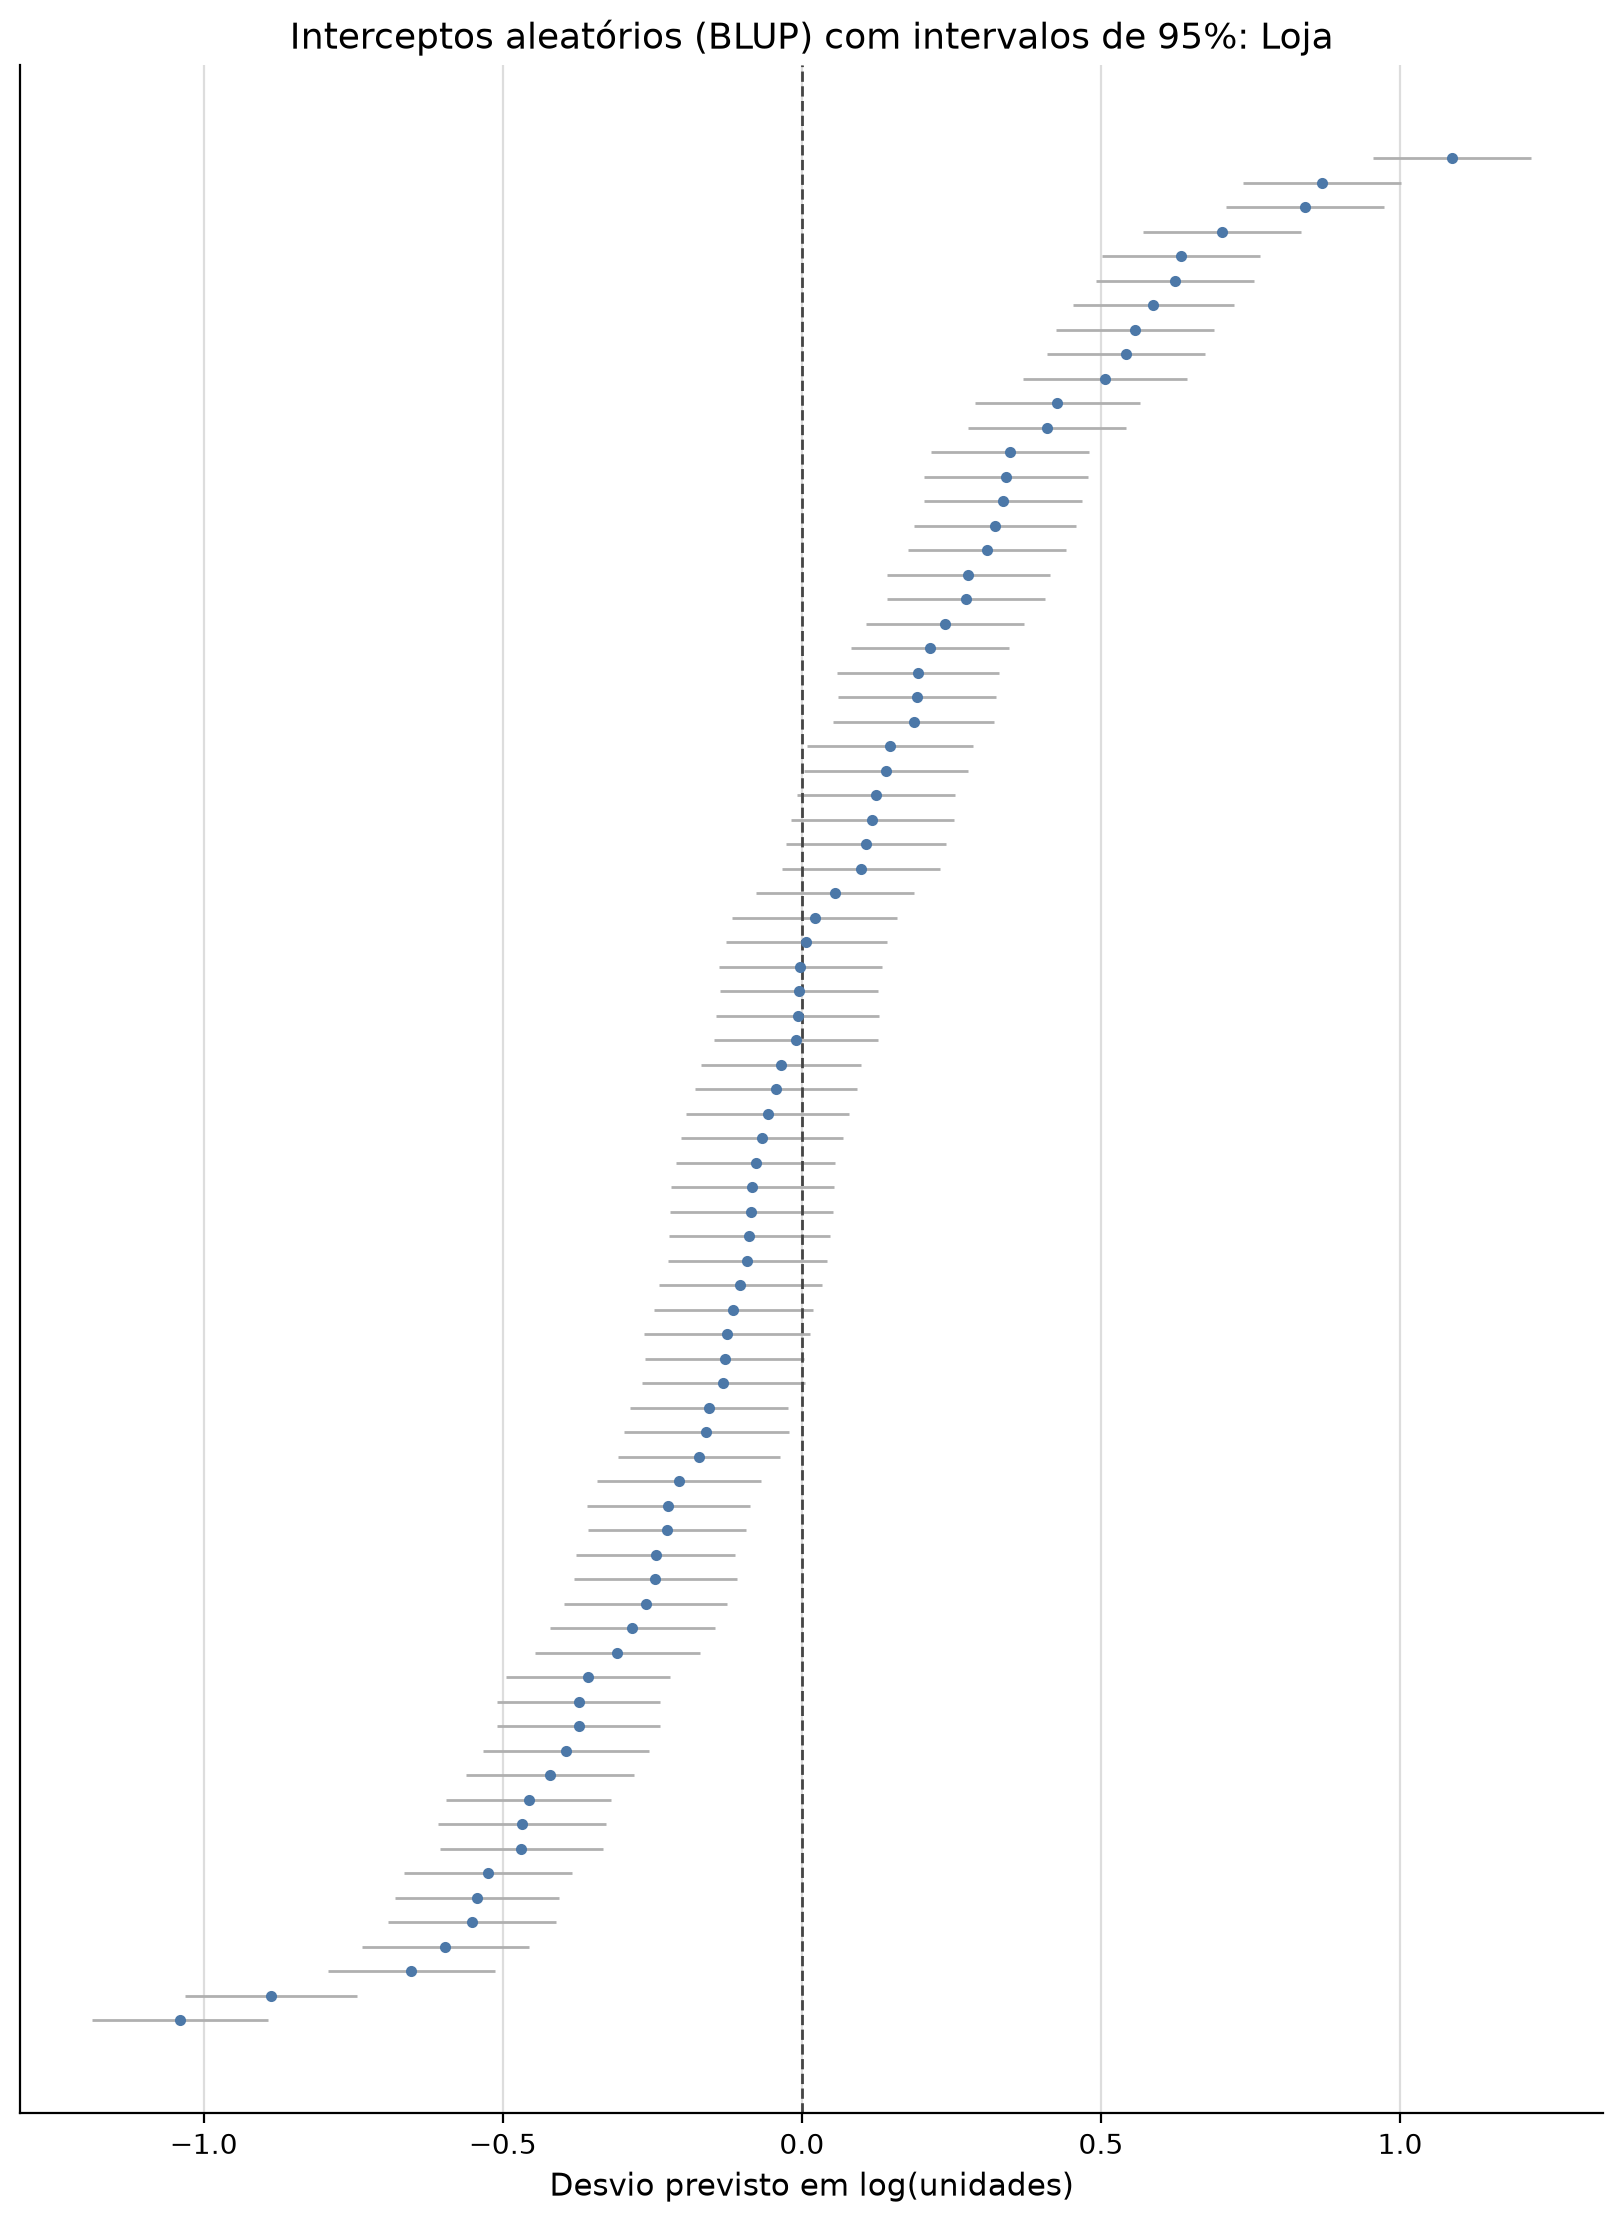

In [8]:
fig = viz.plot_caterpillar(run.load_table("ranef_store"), LANG, "STORE_NUM")

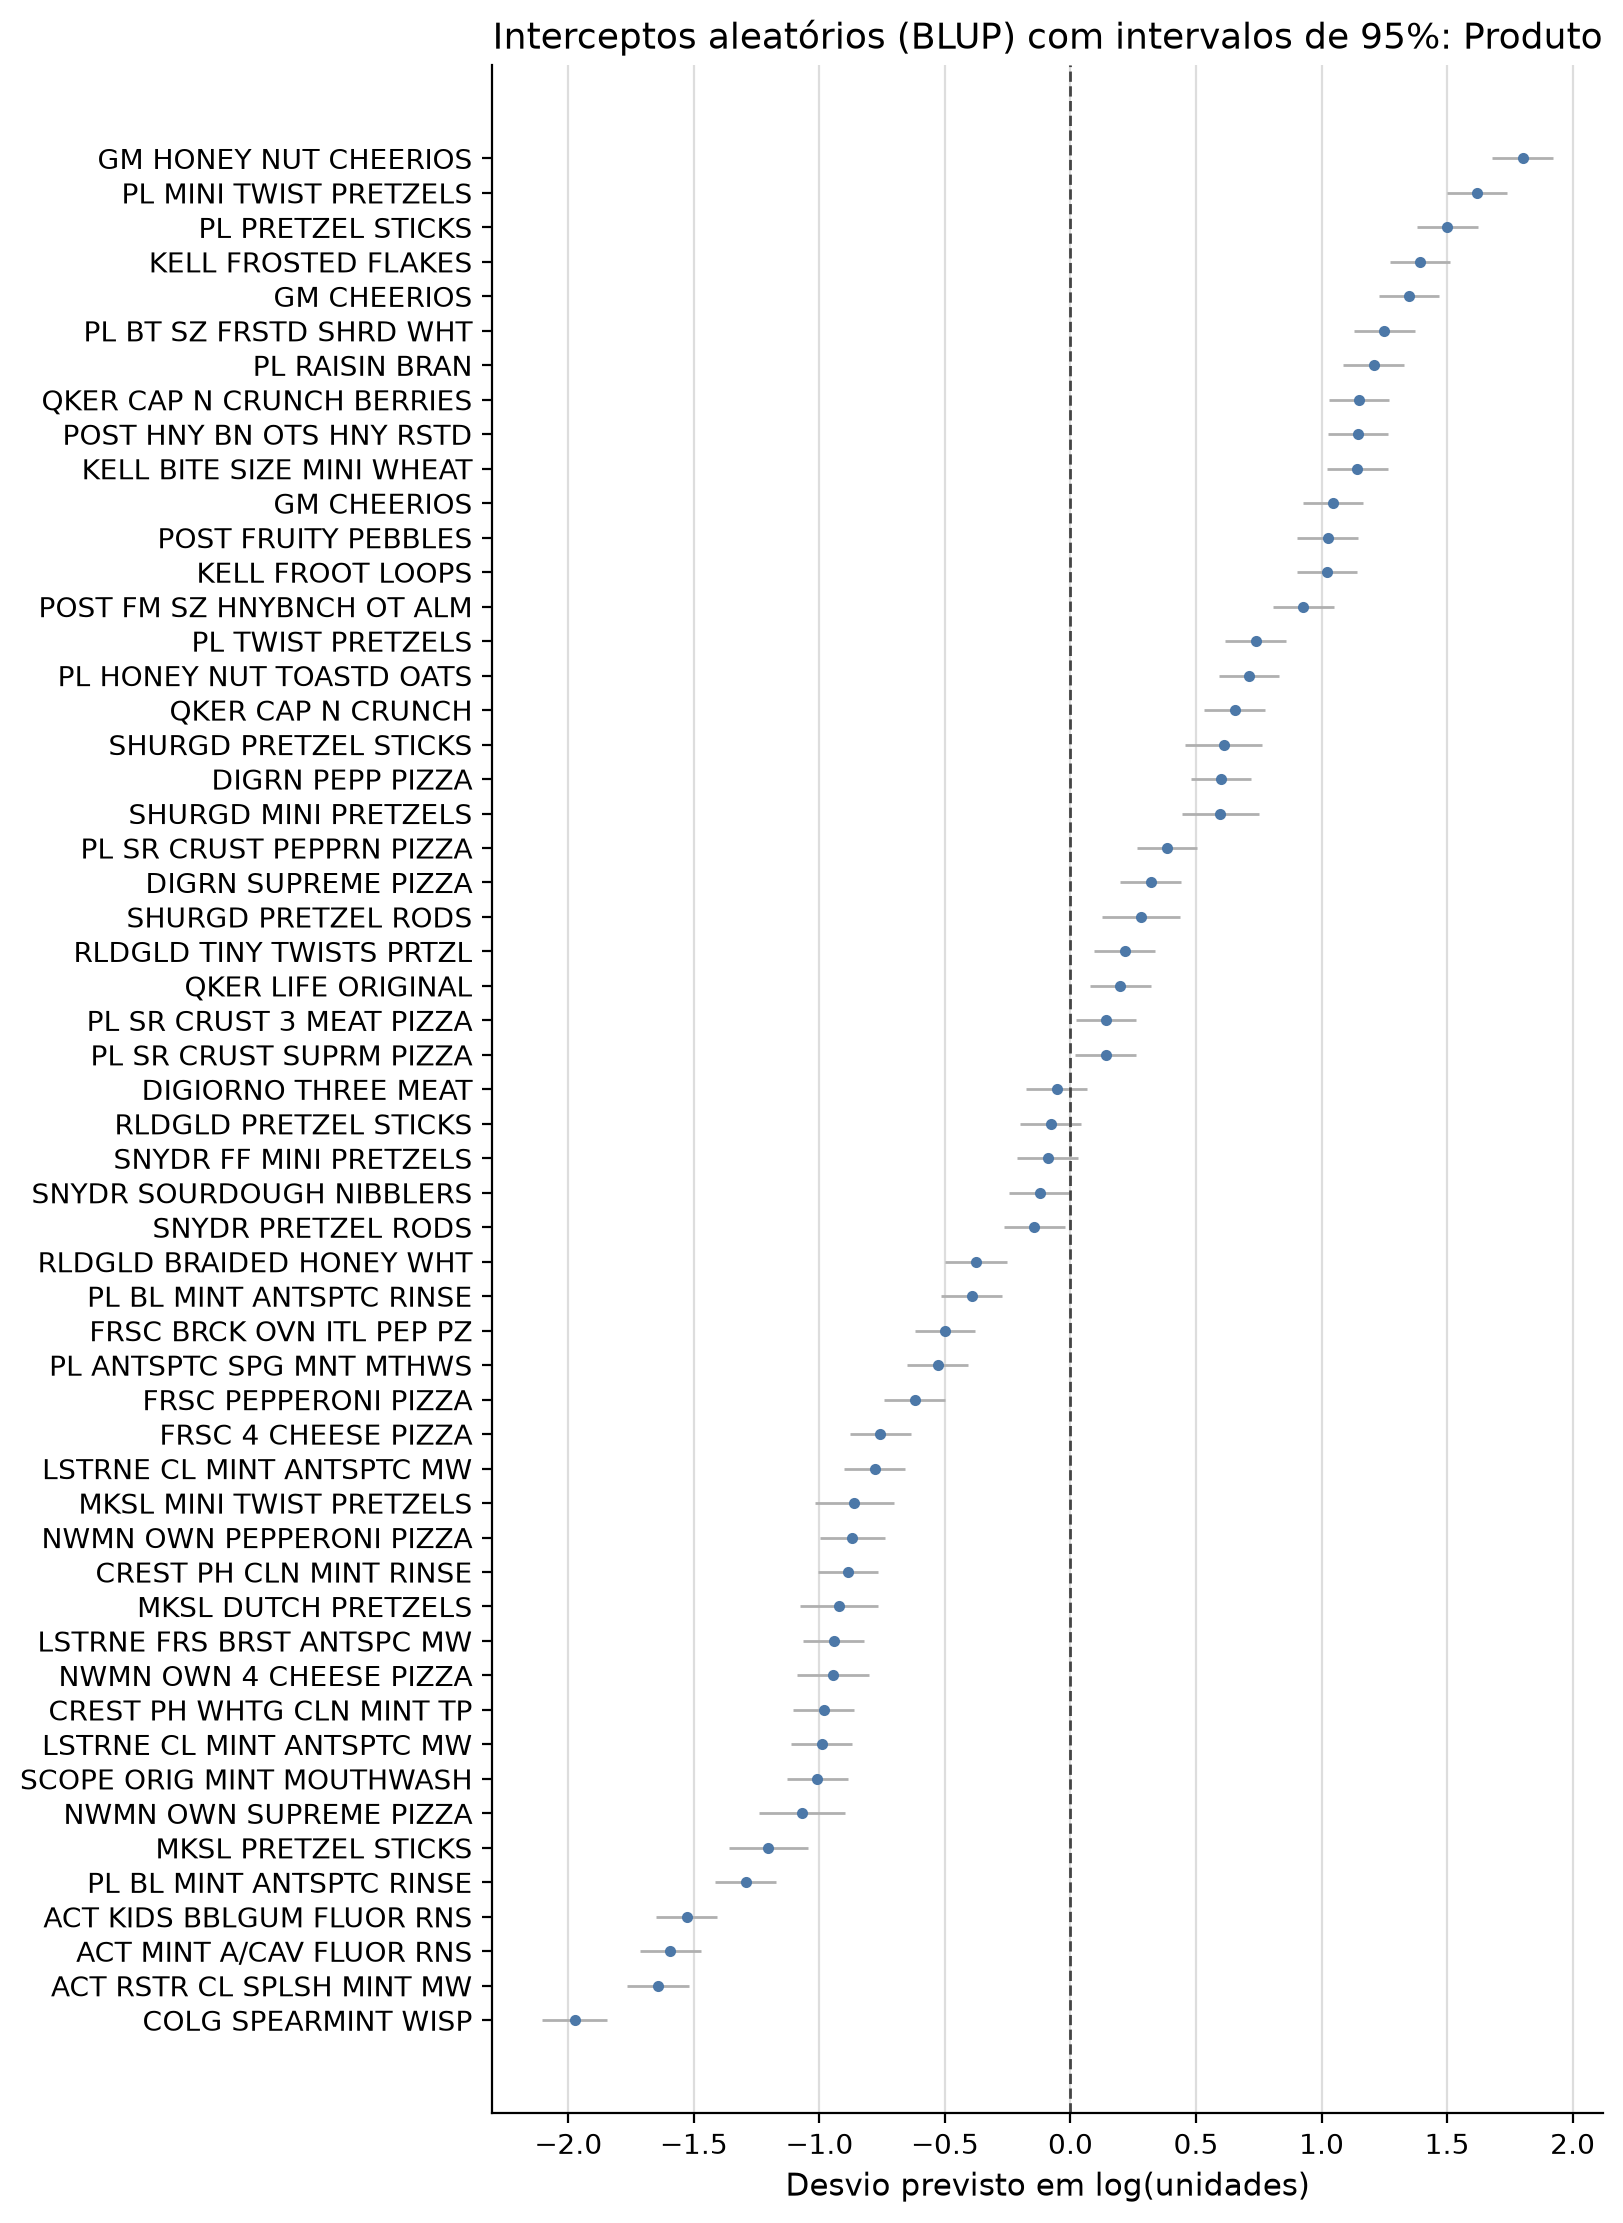

In [9]:
products = pd.read_parquet(PROCESSED_DIR / "panel.parquet", columns=["UPC", "DESCRIPTION"]).drop_duplicates("UPC")
labels = dict(zip(products["UPC"].astype(str), products["DESCRIPTION"], strict=True))
fig = viz.plot_caterpillar(run.load_table("ranef_product"), LANG, "UPC", labels=labels)

Os BLUPs são desvios previstos para os grupos, encolhidos em direção à média geral (Henderson, 1975; Robinson, 1991). No caso ilustrativo de um único agrupamento com intercepto aleatório, o desvio observado é multiplicado por σ²ᵤ / (σ²ᵤ + σ²ₑ/n). Quanto menor o número de observações do grupo (n), maior é o encolhimento, chamado de *partial pooling*. No M4, os desvios-padrão condicionais são de cerca de 0,07 para lojas e 0,06 para produtos. Os intervalos são estreitos em relação à dispersão entre grupos, sobretudo entre produtos.

## 6. Verificação cruzada com o lme4

O modelo M1 (efeito aleatório só de loja) foi ajustado também com o `MixedLM` do statsmodels (Seabold & Perktold, 2010), uma implementação independente em Python, e comparado ao lme4 (R; Bates et al., 2015).

In [10]:
display(run.load_table("crosscheck"))

,component,statsmodels,lme4,rel_diff
0,STORE_NUM,0.1001,0.1007,0.0060
1,Residual,1.4020,1.4020,0.0000


A diferença relativa entre as estimativas da variância residual é de 1,3e-6. Para a variância de loja, a diferença é de 0,6% (0,1001 contra 0,1007). O `MixedLM` foi usado nessa verificação com um único agrupamento. Efeitos cruzados no `MixedLM` exigem um grupo único com `vc_formula`. A sintaxe direta de efeitos cruzados motivou a escolha do lme4 para os demais modelos (decisão D1). O desempenho de `MixedLM` com efeitos cruzados neste volume ficou fora da verificação.

## 7. Conclusões e próximo passo

No M4, produtos respondem por 57,2% da variância de log(unidades), lojas por 9,6%, a interação loja × produto por 8,5% e o resíduo por 24,6%. Os testes de razão de verossimilhanças com correção de fronteira dão evidência para cada componente de agrupamento.

O M4 estima uma correlação de 75,4% entre duas semanas do mesmo par e de 9,6% entre produtos diferentes na mesma loja. Na verificação com um único agrupamento, lme4 e statsmodels produziram estimativas próximas.

O notebook 03 acrescentará os efeitos fixos de preço e promoção. Depois, serão estudadas inclinações aleatórias, cuja especificação exige cuidado no `MixedLM`. Com `groups='g'` e `re_formula='x'`, um componente `vc_formula={'h': '0 + x'}` não cria uma inclinação por nível de `h`: ele gera a coluna `x` dentro de cada grupo `g`, isto é, uma segunda variância de inclinação no nível de `g`, duplicada da que `re_formula` já estima, e não inclui intercepto por `h`. O resultado são componentes não identificáveis, que tendem a falhar na convergência ou a ter variância nula. A especificação por nível de `h` seria `vc_formula={'h': '0 + C(h)', 'h_x': '0 + C(h):x'}`, e no lme4 seria `(1 + x | g) + (1 + x | g:h)`. Neste projeto, as inclinações aleatórias foram especificadas diretamente no lme4.

## Referências

Baayen, R. H., Davidson, D. J., & Bates, D. M. (2008). Mixed-effects modeling with crossed random effects for subjects and items. *Journal of Memory and Language, 59*(4), 390–412. https://doi.org/10.1016/j.jml.2007.12.005

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Henderson, C. R. (1975). Best linear unbiased estimation and prediction under a selection model. *Biometrics, 31*(2), 423–447. https://doi.org/10.2307/2529430

Pinheiro, J. C., & Bates, D. M. (2000). *Mixed-effects models in S and S-PLUS*. Springer. https://doi.org/10.1007/b98882

Raudenbush, S. W., & Bryk, A. S. (2002). *Hierarchical linear models: Applications and data analysis methods* (2nd ed.). Sage. (verificação parcial: ano da edição não conferido em fonte primária)

Robinson, G. K. (1991). That BLUP is a good thing: The estimation of random effects. *Statistical Science, 6*(1), 15–32. https://doi.org/10.1214/ss/1177011926

Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. In *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Self, S. G., & Liang, K.-Y. (1987). Asymptotic properties of maximum likelihood estimators and likelihood ratio tests under nonstandard conditions. *Journal of the American Statistical Association, 82*(398), 605–610. https://doi.org/10.1080/01621459.1987.10478472

Stram, D. O., & Lee, J. W. (1994). Variance components testing in the longitudinal mixed effects model. *Biometrics, 50*(4), 1171–1177. https://doi.org/10.2307/2533455